# Prompt Guard: Milestone 2A part 2, adding harmless prompts

**The problem.** Every text in our dataset contains personal data. The model has never seen a prompt like
*"Fasse den Text zusammen"*. That is why it produces false alarms on normal business prompts
(*"Erstelle eine Tabelle mit den Umsätzen 2023 ..."* was predicted **block** in the baseline).

**The fix we test here.** We add prompts **without** personal data (decision `allow`) to the training data.
They are built by `src/harmless_data.py`:

| Source | What it is | Used for |
|---|---|---|
| **oasst1** | Real first questions that people typed into a chat assistant (de / en / fr / it), filtered for personal data | train 70 % / validation 15 % / test 15 % |
| **Templates** | Typical office requests written by our team, filled with harmless details | train only (generated text would make measuring too easy) |

**What stays the same** (so the comparison is fair):
- the ai4privacy split (`data/splits.csv`), the policy, the TF-IDF settings,
- `C` and the block threshold from part 1 (`tfidf_tuning.ipynb`), if that model file exists.

So the **only** change is the extra data. If the results change, we know why.

**What we measure**
1. **ai4privacy validation:** do we keep the block recall? (comparable with the baseline and part 1)
2. **Harmless validation (oasst1):** how many real harmless prompts are wrongly blocked or warned?
3. **Own prompts** (`data/own_prompts.csv`, only looked at, never trained on), split by writing style.
   This is our **shortcut check**: the new harmless prompts are short and casual, the PII texts are formal.
   The model could learn the wrong rule *"casual = harmless"*. Then it would let casual prompts with an IBAN through.

**Rules:** train only on train, choose settings on validation, never touch any test part.

**Structure**
1. Setup · 2. Load the data · 3. Settings from part 1 · 4. Turn the texts into numbers · 5. Train ·
6. Before vs. after · 7. Block threshold · 8. Per language · 9. Own prompts and shortcut check ·
10. Response time · 11. Save and log · 12. Conclusion

## 1. Setup

Same settings as in `tfidf_tuning.ipynb`. New is the import of `src/harmless_data.py`.

**Before the first run**, build the harmless data once in a terminal (project folder, venv activated):
```
python src/harmless_data.py
```
It downloads oasst1 (about 40 MB, once) and writes `data/harmless_prompts.csv`.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import joblib
import mlflow

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score, recall_score

sys.path.append("../src")
from data_utils import load_all_splits, split_fingerprint
from harmless_data import load_harmless, harmless_fingerprint

SEED = 42
CLASSES = ["allow", "warn", "block"]
PROJECT_DIR = Path("..").resolve()
MODEL_DIR = PROJECT_DIR / "models"

TARGET_RECALL_BLOCK = 0.95       # at least 95 % of block texts must be blocked
TARGET_FALSE_BLOCK = 0.05        # at most 5 % of harmless (allow) texts may be blocked

with open(PROJECT_DIR / "config" / "policy.yaml", encoding="utf-8") as f:
    POLICY_VERSION = str(yaml.safe_load(f)["version"])

BLUE = "#2a78d6"
ORANGE = "#eb6834"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# MLflow: shared server if MLFLOW_TRACKING_URI is set (e.g. in .env), otherwise local (same as the other notebooks)
try:
    from dotenv import load_dotenv
    load_dotenv(PROJECT_DIR / ".env")
except ImportError:
    pass
if os.getenv("MLFLOW_TRACKING_URI"):
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard")
else:
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}")
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard", artifact_location=(PROJECT_DIR / "mlruns").as_uri())
mlflow.set_experiment("promptguard")
print("Policy version:", POLICY_VERSION, "| MLflow:", mlflow.get_tracking_uri())

c:\Users\olga9\Desktop\Studium Heilbronn\Kurse\WiSe26\AIO - AI Operations\AIOps_PromptGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Policy version: 0.1 | MLflow: sqlite:///C:/Users/olga9/Desktop/Studium Heilbronn/Kurse/WiSe26/AIO - AI Operations/AIOps_PromptGuard/mlflow.db


## 2. Load the data

We load both datasets and put them into the same shape: the text (`source_text`), the correct decision
(`decision`), the language and a new column `origin`, so we always know where a text comes from.

In [2]:
splits = load_all_splits()
pii_train, pii_val = splits["train"], splits["validation"]
del splits                                     # no test set in this notebook

harmless_train = load_harmless("train")
harmless_val = load_harmless("validation")
# (we deliberately do not load load_harmless("test"))

SPLIT_FINGERPRINT = split_fingerprint()
HARMLESS_FINGERPRINT = harmless_fingerprint()
print("Split fingerprint:   ", SPLIT_FINGERPRINT)
print("Harmless fingerprint:", HARMLESS_FINGERPRINT)

COLUMNS = ["source_text", "decision", "language"]

def tag(df, origin):
    # keep only the columns we need and add where the text comes from
    return df[COLUMNS].assign(origin=origin)

train = pd.concat([tag(pii_train, "ai4privacy"), tag(harmless_train, "harmless")], ignore_index=True)
val = pd.concat([tag(pii_val, "ai4privacy"), tag(harmless_val, "harmless")], ignore_index=True)

# Overview: how many texts per origin and decision?
display(pd.crosstab([train["origin"]], train["decision"], margins=True).rename_axis("TRAIN"))
display(pd.crosstab([val["origin"]], val["decision"], margins=True).rename_axis("VALIDATION"))
print("Harmless train texts by source:")
display(harmless_train.groupby(["source", "language"]).size().unstack(fill_value=0))

# The full ai4privacy tables (with all their extra columns) are no longer needed:
# train and val above already contain the columns we use. Freeing them saves a lot of memory.
del pii_train, pii_val
import gc
gc.collect()

Split fingerprint:    6afd6a257de1
Harmless fingerprint: 9545499b98fa


decision,allow,block,warn,All
TRAIN,,,,
ai4privacy,11471,46056,88928,146455
harmless,3924,0,0,3924
All,15395,46056,88928,150379


decision,allow,block,warn,All
VALIDATION,,,,
ai4privacy,2457,9868,19055,31380
harmless,564,0,0,564
All,3021,9868,19055,31944


Harmless train texts by source:


language,de,en,fr,it
source,,,,
oasst1,235,2103,167,83
templates,883,453,0,0


1361

**How to read this:** the harmless texts are only a small addition (a few percent of train). That is on purpose:
the model should learn what harmless prompts look like, without forgetting how PII looks.

## 3. Settings from part 1

We take `C` and the block threshold from `models/tfidf_logreg_tuned.joblib` (saved by `tfidf_tuning.ipynb`).
That model also serves as our **"before"** model: same settings, but trained **without** harmless prompts.

**Order matters:** run `tfidf_tuning.ipynb` first. If its model file is missing, this notebook stops here
with a clear message instead of silently using other settings (otherwise the before/after comparison would be missing).

In [3]:
before_path = MODEL_DIR / "tfidf_logreg_tuned.joblib"

# Stop with a clear message if part 1 has not been run yet.
# Without this model we would have no "before" model and would not know the tuned C / threshold.
if not before_path.exists():
    raise FileNotFoundError(
        "models/tfidf_logreg_tuned.joblib is missing. "
        "Please run notebooks/tfidf_tuning.ipynb first (Run All), then run this notebook again."
    )

before = joblib.load(before_path)
C = float(before["pipeline"].named_steps["logreg"].C)          # the C chosen in part 1
BLOCK_THRESHOLD_BEFORE = float(before["block_threshold"])      # the threshold chosen in part 1
print(f"Loaded part 1 model: C = {C}, block threshold = {BLOCK_THRESHOLD_BEFORE}")

Loaded part 1 model: C = 30.0, block threshold = 0.2


## 4. Turn the texts into numbers

Same TF-IDF settings as before, fitted **only on the new train set** (ai4privacy train + harmless train).

In [4]:
vectorizer = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(2, 5), min_df=5, max_features=300_000,
    sublinear_tf=True, dtype=np.float32,
)
start = time.perf_counter()
X_train_vec = vectorizer.fit_transform(train["source_text"])
X_val_vec = vectorizer.transform(val["source_text"])
print(f"Vectorising took {time.perf_counter() - start:.0f} s, matrix: {X_train_vec.shape}")

Vectorising took 144 s, matrix: (150379, 300000)


## 5. Train

Same model as in part 1, only the training data is different. This takes a few minutes.

In [5]:
MAX_ITER = 3000
model = LogisticRegression(C=C, class_weight="balanced", max_iter=MAX_ITER, random_state=SEED)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    start = time.perf_counter()
    model.fit(X_train_vec, train["decision"])
    print(f"Training took {time.perf_counter() - start:.0f} s")
CONVERGED = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
print("Converged:", CONVERGED)

pipeline = Pipeline([("tfidf", vectorizer), ("logreg", model)])
model_classes = model.classes_

Training took 397 s
Converged: True


## 6. Before vs. after

We need two small helper functions:
- `predict_with_threshold`: the block threshold rule from part 1 (block if p(block) ≥ t, otherwise the better of allow / warn).
- `evaluate`: the same metrics as in part 1.

For the harmless validation set there is nothing to block, so we look at a simpler question:
**what share of these harmless prompts gets allow, warn or block?** Ideally: (almost) everything allow.

In [6]:
def predict_with_threshold(proba, classes, threshold):
    classes = list(classes)
    if threshold is None:                       # no threshold -> default rule: highest probability wins
        return np.array(classes)[proba.argmax(axis=1)]
    p_block = proba[:, classes.index("block")]
    other = [c for c in classes if c != "block"]
    best_other = np.array(other)[proba[:, [classes.index(c) for c in other]].argmax(axis=1)]
    return np.where(p_block >= threshold, "block", best_other)


def evaluate(y_true, y_pred) -> dict:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    is_allow, is_warn = y_true == "allow", y_true == "warn"
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "recall_block": recall_score(y_true, y_pred, labels=["block"], average="macro", zero_division=0),
        "recall_warn": recall_score(y_true, y_pred, labels=["warn"], average="macro", zero_division=0),
        "recall_allow": recall_score(y_true, y_pred, labels=["allow"], average="macro", zero_division=0),
        "false_block_allow": float((y_pred[is_allow] == "block").mean()) if is_allow.any() else np.nan,
        "false_block_warn": float((y_pred[is_warn] == "block").mean()) if is_warn.any() else np.nan,
    }


def harmless_shares(y_pred) -> dict:
    # share of harmless prompts that end up as allow / warn / block
    y_pred = np.asarray(y_pred)
    return {f"harmless -> {c}": float((y_pred == c).mean()) for c in CLASSES}


is_pii = (val["origin"] == "ai4privacy").to_numpy()
is_harmless = ~is_pii

In [7]:
rows = []

def add_rows(name, proba, classes, threshold):
    pred = predict_with_threshold(proba, classes, threshold)
    rows.append({
        "model": name,
        "block threshold": "argmax" if threshold is None else threshold,
        **{f"ai4privacy {k}": v for k, v in evaluate(val["decision"][is_pii], pred[is_pii]).items()
           if k in ("macro_f1", "recall_block", "false_block_allow")},
        **harmless_shares(pred[is_harmless]),
    })

# BEFORE: part 1 model (no harmless data), with and without its threshold
if before is not None:
    before_proba = before["pipeline"].predict_proba(val["source_text"])
    add_rows("before (no harmless data)", before_proba, before["pipeline"].classes_, None)
    add_rows("before (no harmless data)", before_proba, before["pipeline"].classes_, BLOCK_THRESHOLD_BEFORE)

# AFTER: new model, same rules
val_proba = model.predict_proba(X_val_vec)
add_rows("after (with harmless data)", val_proba, model_classes, None)
if BLOCK_THRESHOLD_BEFORE is not None:
    add_rows("after (with harmless data)", val_proba, model_classes, BLOCK_THRESHOLD_BEFORE)

comparison = pd.DataFrame(rows).round(4)
display(comparison)

,model,block threshold,ai4privacy macro_f1,ai4privacy recall_block,ai4privacy false_block_allow,harmless -> allow,harmless -> warn,harmless -> block
0,before (no harmless data),argmax,0.8769,0.9171,0.0114,0.4113,0.5674,0.0213
1,before (no harmless data),0.2,0.8639,0.9549,0.0216,0.4096,0.5461,0.0443
2,after (with harmless data),argmax,0.8764,0.9170,0.0122,0.9273,0.0603,0.0124
3,after (with harmless data),0.2,0.8648,0.9537,0.0240,0.9220,0.0603,0.0177


**How to read the table**
- `ai4privacy recall_block` should stay about the same. If it drops a lot, the harmless data "pulls" the model too far towards allow.
- `harmless -> block` and `harmless -> warn` should go **down** clearly. These are false alarms on real harmless prompts.

## 7. Block threshold, chosen again

The new data changes the probabilities, so the best threshold may be different now. Same procedure and same rule
as in part 1, but now on the **combined** validation set: the allow class includes the real harmless prompts,
so `false_block_allow` finally measures false alarms on harmless text.

Rule (written down before looking at the numbers):
1. If thresholds reach **both** targets, take the **highest** of them.
2. Otherwise take the best recall block among the thresholds with **≤ 5 %** false alarms.

In [8]:
rows = []
for t in [0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10, 0.05]:
    pred = predict_with_threshold(val_proba, model_classes, t)
    m = evaluate(val["decision"], pred)
    m["harmless -> block"] = float((pred[is_harmless] == "block").mean())
    rows.append({"threshold": t, **m})
sweep = pd.DataFrame(rows)
sweep["meets both targets"] = (sweep["recall_block"] >= TARGET_RECALL_BLOCK) & (sweep["false_block_allow"] <= TARGET_FALSE_BLOCK)
display(sweep.round(4))

both = sweep[sweep["meets both targets"]]
if len(both):
    BLOCK_THRESHOLD = float(both["threshold"].max()); reason = "highest threshold that reaches both targets"
else:
    safe = sweep[sweep["false_block_allow"] <= TARGET_FALSE_BLOCK]
    if len(safe):
        BLOCK_THRESHOLD = float(safe.loc[safe["recall_block"].idxmax(), "threshold"])
        reason = "both targets not reachable; best recall block with <= 5 % false alarms"
    else:
        BLOCK_THRESHOLD = 0.5; reason = "even 0.5 has > 5 % false alarms; keep 0.5"

y_val_pred = predict_with_threshold(val_proba, model_classes, BLOCK_THRESHOLD)
final_metrics = evaluate(val["decision"], y_val_pred)
final_metrics["harmless_to_block"] = float((y_val_pred[is_harmless] == "block").mean())
final_metrics["harmless_to_warn"] = float((y_val_pred[is_harmless] == "warn").mean())
print(f"Chosen threshold: {BLOCK_THRESHOLD} ({reason})")
display(pd.Series(final_metrics).round(4).to_frame("combined validation"))

,threshold,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,harmless -> block,meets both targets
0,0.50,0.8862,0.9149,0.9244,0.8606,0.0109,0.0355,0.0124,False
1,0.45,0.8858,0.9221,0.9195,0.8600,0.0126,0.0404,0.0124,False
2,0.40,0.8847,0.9278,0.9140,0.8590,0.0139,0.0461,0.0124,False
3,0.35,0.8834,0.9342,0.9075,0.8583,0.0152,0.0527,0.0124,False
4,0.30,0.8813,0.9409,0.8993,0.8573,0.0169,0.0612,0.0142,False
5,0.25,0.8788,0.9472,0.8912,0.8557,0.0192,0.0693,0.0142,False
6,0.20,0.8747,0.9537,0.8796,0.8524,0.0228,0.0812,0.0177,True
7,0.15,0.8687,0.9601,0.8641,0.8491,0.0278,0.0970,0.0177,True
8,0.10,0.8576,0.9675,0.8367,0.8428,0.0361,0.1256,0.0213,True
9,0.05,0.8356,0.9788,0.7846,0.8299,0.0540,0.1795,0.0248,False


Chosen threshold: 0.2 (highest threshold that reaches both targets)


,combined validation
macro_f1,0.8747
recall_block,0.9537
recall_warn,0.8796
recall_allow,0.8524
false_block_allow,0.0228
false_block_warn,0.0812
harmless_to_block,0.0177
harmless_to_warn,0.0603


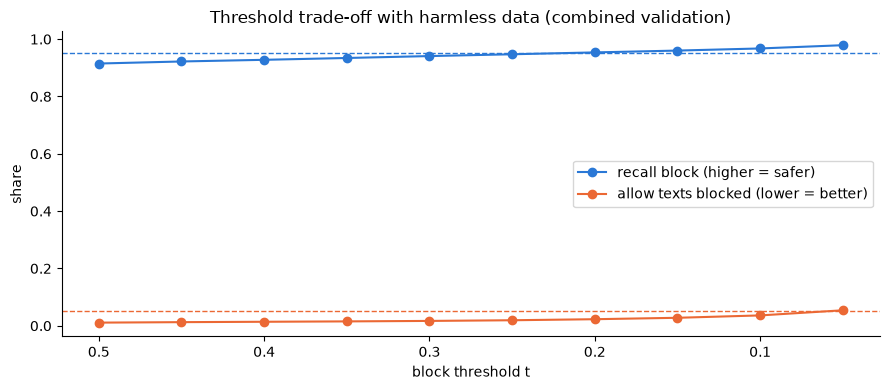

In [9]:
fig, ax = plt.subplots()
ax.plot(sweep["threshold"], sweep["recall_block"], marker="o", color=BLUE, label="recall block (higher = safer)")
ax.plot(sweep["threshold"], sweep["false_block_allow"], marker="o", color=ORANGE, label="allow texts blocked (lower = better)")
ax.axhline(TARGET_RECALL_BLOCK, color=BLUE, linestyle="--", linewidth=1)
ax.axhline(TARGET_FALSE_BLOCK, color=ORANGE, linestyle="--", linewidth=1)
ax.invert_xaxis()
ax.set_xlabel("block threshold t")
ax.set_ylabel("share")
ax.set_title("Threshold trade-off with harmless data (combined validation)")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

## 8. Per language

German matters most. Note: oasst1 has much more English than German, so the German harmless part is smaller.

In [10]:
rows = []
for language, part in val.assign(pred=y_val_pred).groupby("language"):
    h = part[part["origin"] == "harmless"]
    rows.append({"language": language, "texts": len(part),
                 **evaluate(part["decision"], part["pred"]),
                 "harmless texts": len(h),
                 "harmless -> block": float((h["pred"] == "block").mean()) if len(h) else np.nan})
per_language = pd.DataFrame(rows).set_index("language").round(4)
display(per_language)

,texts,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,harmless texts,harmless -> block
language,,,,,,,,,
de,7975,0.8666,0.9555,0.8738,0.8323,0.0344,0.0908,53,0.0566
en,6971,0.8803,0.9485,0.8686,0.8756,0.0204,0.0818,449,0.0134
fr,9338,0.8782,0.9535,0.8903,0.8532,0.0146,0.0753,46,0.0000
it,7660,0.8671,0.9565,0.8821,0.8360,0.0244,0.0778,16,0.0625


## 9. Own prompts and the shortcut check

`data/own_prompts.csv` has 200 prompts we wrote ourselves (80 allow, 60 warn, 60 block, all German, because our product targets German companies).
The column `style` says whether a prompt is written **formal** or **casual** (quick chat message).

**We only look at these results. We never change `C` or the threshold because of them.**

The **shortcut check** compares recall block for casual vs. formal prompts, before and after.
If casual recall block drops after adding the harmless data, the model has learned "casual = harmless".

In [11]:
own = pd.read_csv(PROJECT_DIR / "data" / "own_prompts.csv")

def own_report(name, pipe, threshold):
    proba = pipe.predict_proba(own["prompt"].tolist())
    pred = predict_with_threshold(proba, pipe.classes_, threshold)
    out = []
    for style_name, mask in [("all", np.ones(len(own), bool)),
                             ("formal", (own["style"] == "formal").to_numpy()),
                             ("casual", (own["style"] == "casual").to_numpy())]:
        m = evaluate(own["expected_decision"][mask], pred[mask])
        out.append({"model": name, "style": style_name, "prompts": int(mask.sum()),
                    "accuracy": float((pred[mask] == own["expected_decision"].to_numpy()[mask]).mean()),
                    "recall_block": m["recall_block"], "false_block_allow": m["false_block_allow"],
                    "recall_allow": m["recall_allow"]})
    return out, pred

rows = []
if before is not None:
    r, _ = own_report("before", before["pipeline"], BLOCK_THRESHOLD_BEFORE)
    rows += r
r, own_pred = own_report("after", pipeline, BLOCK_THRESHOLD)
rows += r
own_summary = pd.DataFrame(rows).round(3)
display(own_summary)

OWN_ALL = own_summary[(own_summary["model"] == "after") & (own_summary["style"] == "all")].iloc[0]
OWN_CASUAL = own_summary[(own_summary["model"] == "after") & (own_summary["style"] == "casual")].iloc[0]

,model,style,prompts,accuracy,recall_block,false_block_allow,recall_allow
0,before,all,200,0.650,0.933,0.150,0.288
1,before,formal,162,0.648,0.978,0.147,0.294
2,before,casual,38,0.658,0.800,0.167,0.250
3,after,all,200,0.785,0.917,0.088,0.825
4,after,formal,162,0.790,0.956,0.074,0.824
5,after,casual,38,0.763,0.800,0.167,0.833


In [12]:
# All prompts the new model gets wrong, so we can discuss them in the team
own["predicted"] = own_pred
wrong = own[own["predicted"] != own["expected_decision"]]
print(f"Wrong: {len(wrong)} of {len(own)}")
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 300):
    display(wrong[["prompt", "expected_decision", "predicted", "category", "style"]])

Wrong: 43 of 200


,prompt,expected_decision,predicted,category,style
10,Bitte prüfe die Rechnungsnummer RE-2024-00817 auf Formatfehler.,allow,block,tricky number,formal
12,"Was bedeutet die Fehlermeldung ""HTTP 503 Service Unavailable""?",allow,warn,harmless technical,formal
18,"bestellung 4500123987 hängt im sap, was tun?",allow,block,tricky number,casual
32,was ist nochmal der unterschied zwischen pin und tan,allow,block,tricky keyword,casual
37,"Unsere Ticketnummer ist INC0045821, schreib eine Statusmeldung an die Fachabteilung.",allow,warn,tricky number,formal
43,"Formuliere eine Antwort auf eine Kundenbeschwerde über eine verspätete Lieferung, ohne Namen.",allow,warn,harmless,formal
47,Schreibe eine Einladung zur Weihnachtsfeier am 18.12. ab 18 Uhr im Ratskeller.,allow,warn,harmless date/time,formal
49,Unsere Passwort-Richtlinie verlangt 12 Zeichen. Formuliere eine Rundmail dazu.,allow,block,tricky keyword,formal
53,"Hilf mir, ein Feedbackgespräch mit einem Teammitglied vorzubereiten.",allow,warn,harmless,formal
55,Schreibe eine E-Mail an anna.schmidt@firma.de wegen des Termins am Montag.,warn,allow,email,formal


## 10. Response time

Same method as before: 1,000 single prompts from validation.

In [13]:
sample = val["source_text"].sample(1000, random_state=SEED).tolist()
times_ms = []
for prompt in sample:
    start = time.perf_counter()
    predict_with_threshold(pipeline.predict_proba([prompt]), model_classes, BLOCK_THRESHOLD)
    times_ms.append((time.perf_counter() - start) * 1000)
LATENCY_MEDIAN_MS = float(np.median(times_ms))
LATENCY_P95_MS = float(np.percentile(times_ms, 95))
print(f"Median: {LATENCY_MEDIAN_MS:.2f} ms | 95th percentile: {LATENCY_P95_MS:.2f} ms")

Median: 2.98 ms | 95th percentile: 5.19 ms


## 11. Save and log

Saved as `models/tfidf_logreg_harmless.joblib` (pipeline + threshold, same format as part 1) and logged as the
MLflow run `tfidf_logreg_harmless`. New parameters: the harmless data fingerprint and how many harmless texts were used,
so anybody can see which data version a run used.

In [14]:
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "tfidf_logreg_harmless.joblib"
joblib.dump({"pipeline": pipeline, "block_threshold": BLOCK_THRESHOLD, "classes": list(model_classes),
             "split_fingerprint": SPLIT_FINGERPRINT, "harmless_fingerprint": HARMLESS_FINGERPRINT,
             "policy_version": POLICY_VERSION}, model_path)

reports = PROJECT_DIR / "reports"
reports.mkdir(exist_ok=True)
comparison.to_csv(reports / "harmless_before_after.csv", index=False)
own_summary.to_csv(reports / "harmless_own_prompts.csv", index=False)

with mlflow.start_run(run_name="tfidf_logreg_harmless"):
    mlflow.set_tags({"milestone": "M2", "experiment_part": "A_harmless_data", "candidate": "true"})
    mlflow.log_params({
        "model": "tfidf_logreg", "analyzer": "char_wb", "ngram_range": "2-5", "min_df": 5,
        "max_features": 300_000, "C": C, "class_weight": "balanced", "max_iter": MAX_ITER,
        "block_threshold": BLOCK_THRESHOLD, "threshold_reason": reason,
        "split_fingerprint": SPLIT_FINGERPRINT, "policy_version": POLICY_VERSION,
        "harmless_fingerprint": HARMLESS_FINGERPRINT,
        "n_harmless_train": len(harmless_train),
        "n_harmless_train_oasst1": int((harmless_train["source"] == "oasst1").sum()),
        "n_harmless_train_templates": int((harmless_train["source"] == "templates").sum()),
    })
    # val_* = combined validation (ai4privacy + harmless)
    mlflow.log_metrics({f"val_{k}": v for k, v in final_metrics.items()})
    mlflow.log_metrics({
        "val_de_recall_block": per_language.loc["de", "recall_block"],
        "val_de_false_block_allow": per_language.loc["de", "false_block_allow"],
        "own_prompts_accuracy": OWN_ALL["accuracy"],
        "own_prompts_recall_block": OWN_ALL["recall_block"],
        "own_prompts_false_block_allow": OWN_ALL["false_block_allow"],
        "own_prompts_casual_recall_block": OWN_CASUAL["recall_block"],
        "latency_median_ms": LATENCY_MEDIAN_MS, "latency_p95_ms": LATENCY_P95_MS,
        "converged": int(CONVERGED),
    })
    for p in [model_path, reports / "harmless_before_after.csv", reports / "harmless_own_prompts.csv"]:
        mlflow.log_artifact(str(p))
print("Run logged to MLflow.")

Run logged to MLflow.


## 12. Conclusion

_Fill in after running the notebook._

| | Before (part 1, no harmless data) | After (with harmless data) | Target |
|---|---|---|---|
| ai4privacy recall block | __ | __ | ≥ 0.95 |
| Real harmless prompts blocked (oasst1 validation) | __ | __ | ≤ 0.05 |
| Real harmless prompts warned | __ | __ | as low as possible |
| Own prompts: accuracy | __ | __ | |
| Own prompts: harmless blocked | __ | __ | ≤ 0.05 |
| Own prompts: recall block casual / formal | __ / __ | __ / __ | no drop for casual |
| Response time p95 | __ | __ | < 100 ms |

**Did the harmless data help?** _(fewer false alarms? at what cost in recall block?)_

**Shortcut check:** _(did casual block prompts get worse? if yes: add casual PII examples to training, plan B)_

**Limitations**
- oasst1 is mostly English; the German harmless part is small.
- The PII filter of `harmless_data.py` is a regex: it removes e-mails, numbers, IBANs and given passwords,
  but **not names**. Some oasst1 prompts mention people (often public figures, e.g. "Wer war Goethe?").
  We label them allow on purpose: a question about a public figure is not a data leak.
- The template prompts are generated, so they are only used for training, never for measuring.